# NLP Analysis — Reel Variance

Sentiment analysis of IMDb review text (Kaggle IMDb Spoiler dataset).



In [5]:
import re
import html
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tag.perceptron import PerceptronTagger


NLTK_RESOURCES = {
    'punkt_tab': 'tokenizers/punkt_tab',
    'stopwords': 'corpora/stopwords',
    'wordnet': 'corpora/wordnet.zip',
    'omw-1.4': 'corpora/omw-1.4.zip',
    'averaged_perceptron_tagger_eng': 'taggers/averaged_perceptron_tagger_eng',
}
for pkg, path in NLTK_RESOURCES.items():
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(pkg, quiet=True)

## Load data

In [6]:
DATA_DIR = 'Data/IMDB_Spoilers_DataSet'

reviews = pd.read_json(f'{DATA_DIR}/IMDB_reviews.json', lines=True)
movies = pd.read_json(f'{DATA_DIR}/IMDB_movie_details.json', lines=True)
reviews['rating'] = pd.to_numeric(reviews['rating'], errors='coerce')

print(reviews.shape, movies.shape)
reviews.head()

(573913, 7) (1572, 7)


,review_date,movie_id,user_id,is_spoiler,review_text,rating,review_summary
0,10 February 2006,tt0111161,ur1898687,True,"In its Oscar year, Shawshank Redemption (writt...",10,A classic piece of unforgettable film-making.
1,6 September 2000,tt0111161,ur0842118,True,The Shawshank Redemption is without a doubt on...,10,Simply amazing. The best film of the 90's.
2,3 August 2001,tt0111161,ur1285640,True,I believe that this film is the best story eve...,8,The best story ever told on film
3,1 September 2002,tt0111161,ur1003471,True,"**Yes, there are SPOILERS here**This film has ...",10,Busy dying or busy living?
4,20 May 2004,tt0111161,ur0226855,True,At the heart of this extraordinary movie is a ...,8,"Great story, wondrously told and acted"


# Review Summary Preprocessing



In [7]:
print('Missing summaries:', reviews['review_summary'].isna().sum())
print('Summary length (words):')
reviews['review_summary'].fillna('').str.split().str.len().describe()

Missing summaries: 0
Summary length (words):


count    573913.000000
mean          5.966650
std           3.930131
min           0.000000
25%           3.000000
50%           5.000000
75%           8.000000
max         323.000000
Name: review_summary, dtype: float64

## Step 1 — Cleaning



In [8]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = html.unescape(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text)                    # HTML tags
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)      # URLs
    text = re.sub(r"won't", 'will not', text)
    text = re.sub(r"can't", 'can not', text)
    text = re.sub(r"n't", ' not', text)                     # negations
    text = re.sub(r"'(s|re|ve|ll|d|m)\b", ' ', text)        # other contractions
    text = re.sub(r'[^a-z\s]', ' ', text)                   # digits & punctuation
    return re.sub(r'\s+', ' ', text).strip()

reviews['summary_clean'] = reviews['review_summary'].map(clean_text)
reviews[['review_summary', 'summary_clean']].head(10)

,review_summary,summary_clean
0,A classic piece of unforgettable film-making.,a classic piece of unforgettable film making
1,Simply amazing. The best film of the 90's.,simply amazing the best film of the
2,The best story ever told on film,the best story ever told on film
3,Busy dying or busy living?,busy dying or busy living
4,"Great story, wondrously told and acted",great story wondrously told and acted
5,"Good , But It Is Overrated By Some",good but it is overrated by some
6,This Movie Saved My Life.,this movie saved my life
7,Movie you can see 1000 times,movie you can see times
8,The Shawshank Redemption,the shawshank redemption
9,"""I'm a convicted murderer who provides sound f...",i a convicted murderer who provides sound fina...


## Step 2 — Tokenization & stopword removal



In [9]:
NEGATIONS = {'no', 'not', 'nor', 'never'}
STOPWORDS = set(stopwords.words('english')) - NEGATIONS

def tokenize(text):
    return [w for w in word_tokenize(text) if w not in STOPWORDS and len(w) > 1]

reviews['tokens'] = reviews['summary_clean'].map(tokenize)
reviews[['summary_clean', 'tokens']].head(10)

,summary_clean,tokens
0,a classic piece of unforgettable film making,"[classic, piece, unforgettable, film, making]"
1,simply amazing the best film of the,"[simply, amazing, best, film]"
2,the best story ever told on film,"[best, story, ever, told, film]"
3,busy dying or busy living,"[busy, dying, busy, living]"
4,great story wondrously told and acted,"[great, story, wondrously, told, acted]"
5,good but it is overrated by some,"[good, overrated]"
6,this movie saved my life,"[movie, saved, life]"
7,movie you can see times,"[movie, see, times]"
8,the shawshank redemption,"[shawshank, redemption]"
9,i a convicted murderer who provides sound fina...,"[convicted, murderer, provides, sound, financi..."


## Step 3 — Stemming



In [10]:
stemmer = PorterStemmer()
reviews['stems'] = reviews['tokens'].map(lambda toks: [stemmer.stem(w) for w in toks])

reviews[['tokens', 'stems']].head(10)

,tokens,stems
0,"[classic, piece, unforgettable, film, making]","[classic, piec, unforgett, film, make]"
1,"[simply, amazing, best, film]","[simpli, amaz, best, film]"
2,"[best, story, ever, told, film]","[best, stori, ever, told, film]"
3,"[busy, dying, busy, living]","[busi, die, busi, live]"
4,"[great, story, wondrously, told, acted]","[great, stori, wondrous, told, act]"
5,"[good, overrated]","[good, overr]"
6,"[movie, saved, life]","[movi, save, life]"
7,"[movie, see, times]","[movi, see, time]"
8,"[shawshank, redemption]","[shawshank, redempt]"
9,"[convicted, murderer, provides, sound, financi...","[convict, murder, provid, sound, financi, plan]"


## Step 4 — Lemmatization



In [11]:
lemmatizer = WordNetLemmatizer()
tagger = PerceptronTagger()

def to_wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

tagged = tagger.tag_sents(reviews['tokens'].tolist())
reviews['lemmas'] = [[lemmatizer.lemmatize(w, to_wordnet_pos(t)) for w, t in sent] for sent in tagged]
reviews[['tokens', 'lemmas']].head(10)

,tokens,lemmas
0,"[classic, piece, unforgettable, film, making]","[classic, piece, unforgettable, film, making]"
1,"[simply, amazing, best, film]","[simply, amaze, best, film]"
2,"[best, story, ever, told, film]","[best, story, ever, tell, film]"
3,"[busy, dying, busy, living]","[busy, die, busy, living]"
4,"[great, story, wondrously, told, acted]","[great, story, wondrously, tell, act]"
5,"[good, overrated]","[good, overrate]"
6,"[movie, saved, life]","[movie, save, life]"
7,"[movie, see, times]","[movie, see, time]"
8,"[shawshank, redemption]","[shawshank, redemption]"
9,"[convicted, murderer, provides, sound, financi...","[convict, murderer, provide, sound, financial,..."


## Comparison: stemming vs. lemmatization

In [12]:
reviews[['review_summary', 'tokens', 'stems', 'lemmas']].head(10)

,review_summary,tokens,stems,lemmas
0,A classic piece of unforgettable film-making.,"[classic, piece, unforgettable, film, making]","[classic, piec, unforgett, film, make]","[classic, piece, unforgettable, film, making]"
1,Simply amazing. The best film of the 90's.,"[simply, amazing, best, film]","[simpli, amaz, best, film]","[simply, amaze, best, film]"
2,The best story ever told on film,"[best, story, ever, told, film]","[best, stori, ever, told, film]","[best, story, ever, tell, film]"
3,Busy dying or busy living?,"[busy, dying, busy, living]","[busi, die, busi, live]","[busy, die, busy, living]"
4,"Great story, wondrously told and acted","[great, story, wondrously, told, acted]","[great, stori, wondrous, told, act]","[great, story, wondrously, tell, act]"
5,"Good , But It Is Overrated By Some","[good, overrated]","[good, overr]","[good, overrate]"
6,This Movie Saved My Life.,"[movie, saved, life]","[movi, save, life]","[movie, save, life]"
7,Movie you can see 1000 times,"[movie, see, times]","[movi, see, time]","[movie, see, time]"
8,The Shawshank Redemption,"[shawshank, redemption]","[shawshank, redempt]","[shawshank, redemption]"
9,"""I'm a convicted murderer who provides sound f...","[convicted, murderer, provides, sound, financi...","[convict, murder, provid, sound, financi, plan]","[convict, murderer, provide, sound, financial,..."


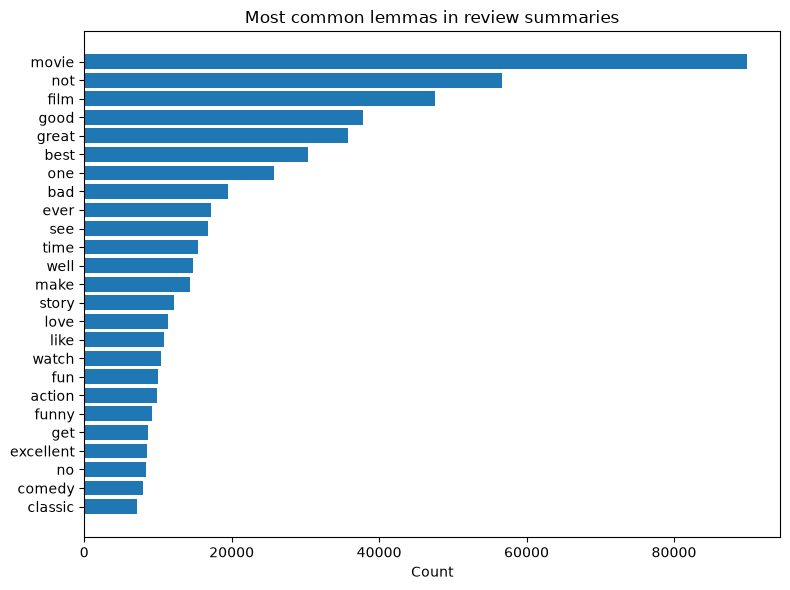

In [14]:
top_lemmas = Counter(w for toks in reviews['lemmas'] for w in toks).most_common(25)
words, counts = zip(*top_lemmas)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(words[::-1], counts[::-1])
ax.set_title('Most common lemmas in review summaries')
ax.set_xlabel('Count')
plt.tight_layout()
plt.show()

# Sentiment Scoring

Model: **DistilBERT fine-tuned on SST-2** (`distilbert-base-uncased-finetuned-sst-2-english`)

In [15]:
import torch
from transformers import pipeline
from tqdm.auto import tqdm

device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
sentiment_model = pipeline(
    'sentiment-analysis',
    model='distilbert-base-uncased-finetuned-sst-2-english',
    device=device,
)
print('Running on:', device)

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 23:10:03.995000 1805 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 12828.50it/s]


Running on: mps


In [16]:
texts = reviews['review_summary'].fillna('').tolist()
CHUNK = 4096

results = []
for i in tqdm(range(0, len(texts), CHUNK)):
    results += sentiment_model(texts[i:i + CHUNK], batch_size=64, truncation=True)

reviews['sentiment_label'] = [r['label'] for r in results]
reviews['sentiment_conf'] = [r['score'] for r in results]
reviews['sentiment_score'] = np.where(reviews['sentiment_label'] == 'POSITIVE', 1, -1) * reviews['sentiment_conf']

reviews[['review_summary', 'rating', 'sentiment_label', 'sentiment_score']].head(10)

100%|██████████| 141/141 [18:14<00:00,  7.77s/it]


,review_summary,rating,sentiment_label,sentiment_score
0,A classic piece of unforgettable film-making.,10,POSITIVE,0.999881
1,Simply amazing. The best film of the 90's.,10,POSITIVE,0.999877
2,The best story ever told on film,8,POSITIVE,0.999841
3,Busy dying or busy living?,10,NEGATIVE,-0.998730
4,"Great story, wondrously told and acted",8,POSITIVE,0.999887
5,"Good , But It Is Overrated By Some",8,POSITIVE,0.670250
6,This Movie Saved My Life.,9,POSITIVE,0.998952
7,Movie you can see 1000 times,10,POSITIVE,0.998849
8,The Shawshank Redemption,10,POSITIVE,0.997546
9,"""I'm a convicted murderer who provides sound f...",10,POSITIVE,0.964487


## Validation against star ratings


Treating **≥7 as positive** and **≤4 as negative**, and leave 5–6 out as ambiguous.

In [17]:
reviews['sentiment_label'].value_counts(normalize=True)

sentiment_label
POSITIVE    0.628909
NEGATIVE    0.371091
Name: proportion, dtype: float64

In [20]:
clear = reviews[(reviews['rating'] >= 7) | (reviews['rating'] <= 4)].copy()
clear['rating_label'] = np.where(clear['rating'] >= 7, 'POSITIVE', 'NEGATIVE')

agreement = (clear['rating_label'] == clear['sentiment_label']).mean()
corr = reviews[['sentiment_score', 'rating']].corr().iloc[0, 1]
print(f'Agreement with rating (>=7 pos, <=4 neg): {agreement:.1%}  (n={len(clear):,})')
print(f'Correlation between sentiment_score and rating: {corr:.3f}')

pd.crosstab(clear['rating_label'], clear['sentiment_label'], normalize='index').round(3)

Agreement with rating (>=7 pos, <=4 neg): 82.4%  (n=499,455)
Correlation between sentiment_score and rating: 0.577


sentiment_label,NEGATIVE,POSITIVE
rating_label,,
NEGATIVE,0.826,0.174
POSITIVE,0.176,0.824


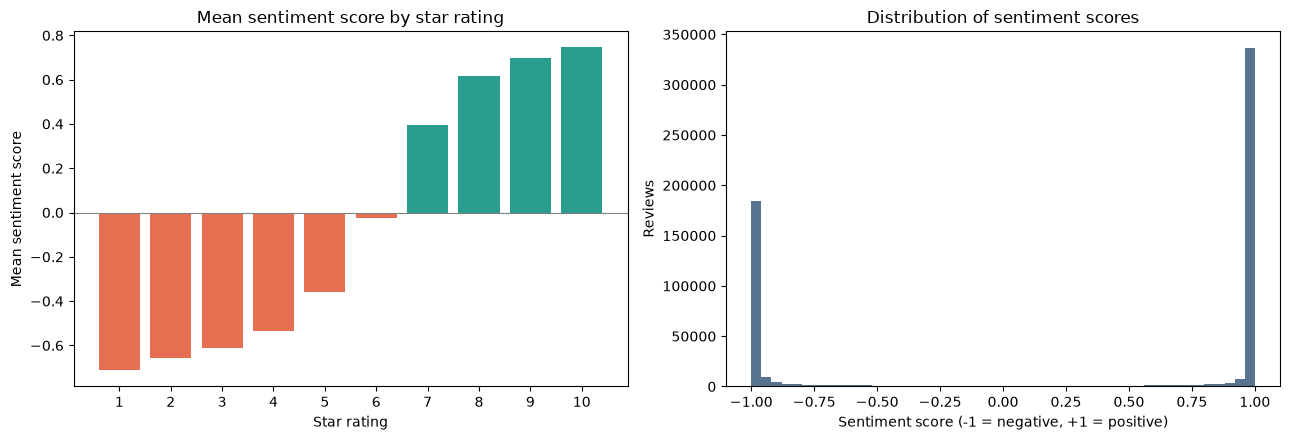

In [18]:
by_rating = reviews.groupby('rating')['sentiment_score'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(by_rating.index, by_rating.values, color=np.where(by_rating.values >= 0, '#2a9d8f', '#e76f51'))
axes[0].axhline(0, color='grey', lw=0.8)
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel('Star rating')
axes[0].set_ylabel('Mean sentiment score')
axes[0].set_title('Mean sentiment score by star rating')

axes[1].hist(reviews['sentiment_score'], bins=50, color='#577590')
axes[1].set_xlabel('Sentiment score (-1 = negative, +1 = positive)')
axes[1].set_ylabel('Reviews')
axes[1].set_title('Distribution of sentiment scores')
plt.tight_layout()
plt.show()

## Where sentiment and rating disagree



In [19]:
cols = ['review_summary', 'rating', 'sentiment_score']
print('High rating (>=9) but strongly negative summary:')
display(reviews[(reviews['rating'] >= 9) & (reviews['sentiment_score'] < -0.95)][cols].sample(10, random_state=0))
print('Low rating (<=2) but strongly positive summary:')
display(reviews[(reviews['rating'] <= 2) & (reviews['sentiment_score'] > 0.95)][cols].sample(10, random_state=0))

High rating (>=9) but strongly negative summary:


,review_summary,rating,sentiment_score
286990,Why does everyone bash this movie?,9,-0.999049
123791,Money Never Buys Happiness,9,-0.998492
162227,- Spoilers - Attempting to explain Cloud Atlas.,10,-0.999577
26611,absolutely unmatchable.,10,-0.991734
114069,Brilliantly hopeless,10,-0.999663
128461,Scary and Insidious,9,-0.977880
514376,PLEASE Don't READ UNLESS SEEN THE FILM,10,-0.994513
24847,Why does Scorsese always end up getting screwe...,10,-0.996579
253896,"Brilliant Movie, but lacks subtlety.",9,-0.975547
310427,"""Fight and you'll never survive...Run and you'...",9,-0.998088


Low rating (<=2) but strongly positive summary:


,review_summary,rating,sentiment_score
166492,Do you have to like this movie???,2,0.981441
548566,"The worst, but funniest DVD I ever bought.",1,0.998964
146110,They're Men... They're Men in Hats,1,0.984077
440175,Wow,1,0.999592
292844,A life action cartoon.,1,0.994386
361767,Final Score: Ocean's 12.....Audience 0,1,0.966235
448136,"Rest in peace, Indy.",1,0.999424
461777,"Awesome trailer, horrible movie",1,0.999528
98467,Dallas dream ending,1,0.999414
225478,"If you liked ""Pitch Perfect,"" Don't Waste Your...",2,0.973264


# Sentiment on the Full Review Text


In [22]:
SAMPLE_SIZE = None   # None = score every review (~2 hours); or e.g. 100_000

tokenizer = sentiment_model.tokenizer
model = sentiment_model.model.eval()
POS_ID = model.config.label2id['POSITIVE']
MAX_BODY, HEAD = 510, 128            # 510 + [CLS] + [SEP] = 512

def build_input(token_ids):
    """Fit a review into the model window: first 128 + last 382 tokens if too long."""
    if len(token_ids) > MAX_BODY:
        token_ids = token_ids[:HEAD] + token_ids[-(MAX_BODY - HEAD):]
    return [tokenizer.cls_token_id] + token_ids + [tokenizer.sep_token_id]

@torch.no_grad()
def score_reviews(texts, batch_size=32):
    """Return sentiment in [-1, +1] (P(positive) - P(negative)) for each text."""
    ids = tokenizer(texts, add_special_tokens=False, truncation=False)['input_ids']
    seqs = [build_input(x) for x in ids]
    order = np.argsort([len(s) for s in seqs])       # similar lengths per batch = faster
    out = np.zeros(len(seqs))
    for i in range(0, len(seqs), batch_size):
        idx = order[i:i + batch_size]
        width = max(len(seqs[j]) for j in idx)
        input_ids = torch.tensor([seqs[j] + [tokenizer.pad_token_id] * (width - len(seqs[j])) for j in idx]).to(model.device)
        mask = torch.tensor([[1] * len(seqs[j]) + [0] * (width - len(seqs[j])) for j in idx]).to(model.device)
        probs = torch.softmax(model(input_ids=input_ids, attention_mask=mask).logits, dim=-1)[:, POS_ID]
        out[idx] = (probs * 2 - 1).cpu().numpy()
    return out

In [23]:
rows = reviews.sample(SAMPLE_SIZE, random_state=0).index if SAMPLE_SIZE else reviews.index
rows = rows.sort_values()

CHUNK = 8192
scores = []
for i in tqdm(range(0, len(rows), CHUNK)):
    scores.append(score_reviews(reviews.loc[rows[i:i + CHUNK], 'review_text'].fillna('').tolist()))

reviews['review_sentiment_score'] = np.nan
reviews.loc[rows, 'review_sentiment_score'] = np.concatenate(scores)
reviews['review_sentiment_label'] = np.where(reviews['review_sentiment_score'] > 0, 'POSITIVE', 'NEGATIVE')
reviews.loc[reviews['review_sentiment_score'].isna(), 'review_sentiment_label'] = np.nan

reviews[['review_summary', 'rating', 'sentiment_score', 'review_sentiment_score']].dropna().head(10)

100%|██████████| 71/71 [4:36:21<00:00, 233.55s/it]   


,review_summary,rating,sentiment_score,review_sentiment_score
0,A classic piece of unforgettable film-making.,10,0.999881,0.995959
1,Simply amazing. The best film of the 90's.,10,0.999877,0.999466
2,The best story ever told on film,8,0.999841,0.999260
3,Busy dying or busy living?,10,-0.998730,0.960135
4,"Great story, wondrously told and acted",8,0.999887,0.997981
5,"Good , But It Is Overrated By Some",8,0.670250,0.127297
6,This Movie Saved My Life.,9,0.998952,0.995156
7,Movie you can see 1000 times,10,0.998849,0.987075
8,The Shawshank Redemption,10,0.997546,0.989354
9,"""I'm a convicted murderer who provides sound f...",10,0.964487,0.995682


## Summary vs. full text


In [24]:
scored = reviews.dropna(subset=['review_sentiment_score']).copy()
clear = scored[(scored['rating'] >= 7) | (scored['rating'] <= 4)]

def agree(df, col):
    return ((df['rating'] >= 7) == (df[col] > 0)).mean()

comparison = pd.DataFrame({
    'Agreement with rating': [agree(clear, 'sentiment_score'), agree(clear, 'review_sentiment_score')],
    'Correlation with rating': [scored[['sentiment_score', 'rating']].corr().iloc[0, 1],
                                scored[['review_sentiment_score', 'rating']].corr().iloc[0, 1]],
}, index=['Summary only', 'Full review text'])
print(f'Reviews scored: {len(scored):,}')
comparison.round(3)

Reviews scored: 573,913


,Agreement with rating,Correlation with rating
Summary only,0.824,0.577
Full review text,0.894,0.736


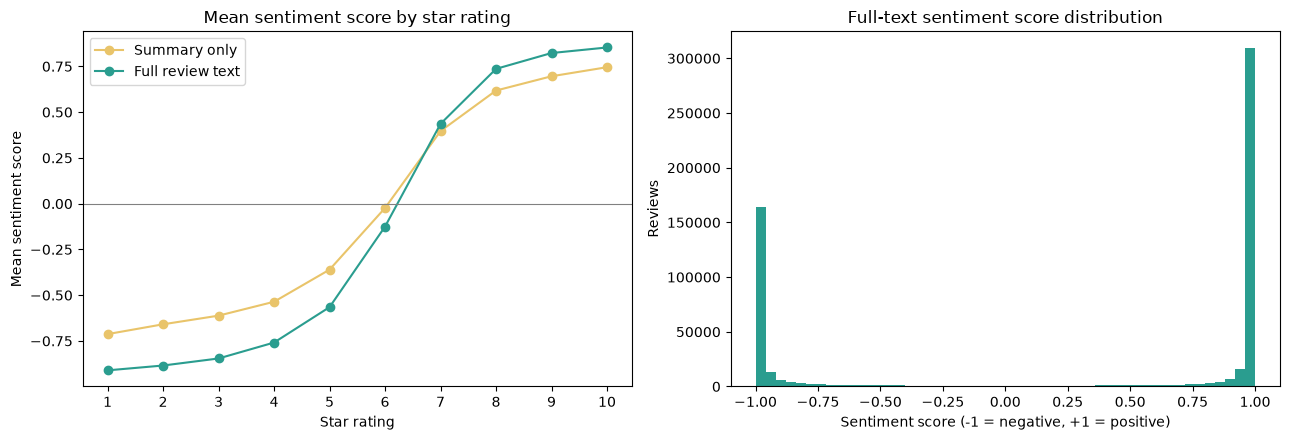

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for col, name, color in [('sentiment_score', 'Summary only', '#e9c46a'), ('review_sentiment_score', 'Full review text', '#2a9d8f')]:
    axes[0].plot(scored.groupby('rating')[col].mean(), marker='o', label=name, color=color)
axes[0].axhline(0, color='grey', lw=0.8)
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel('Star rating')
axes[0].set_ylabel('Mean sentiment score')
axes[0].set_title('Mean sentiment score by star rating')
axes[0].legend()

axes[1].hist(scored['review_sentiment_score'], bins=50, color='#2a9d8f')
axes[1].set_xlabel('Sentiment score (-1 = negative, +1 = positive)')
axes[1].set_ylabel('Reviews')
axes[1].set_title('Full-text sentiment score distribution')
plt.tight_layout()
plt.show()

### Does review length matter?

In [26]:
clear = clear.assign(words=clear['review_text'].str.split().str.len())
clear['length'] = pd.cut(clear['words'], [0, 100, 200, 400, 800, np.inf], labels=['<100', '100-200', '200-400', '400-800', '800+'])

by_len = clear.groupby('length', observed=True).apply(
    lambda g: pd.Series({
        'reviews': len(g),
        'summary agreement': agree(g, 'sentiment_score'),
        'full-text agreement': agree(g, 'review_sentiment_score'),
    }), include_groups=False)
by_len.round(3)

,reviews,summary agreement,full-text agreement
length,,,
<100,55766.0,0.863,0.919
100-200,216663.0,0.838,0.911
200-400,142336.0,0.809,0.884
400-800,69411.0,0.792,0.854
800+,15279.0,0.778,0.835


## Remaining disagreements with the full text

In [27]:
cols = ['review_summary', 'rating', 'review_sentiment_score']
print('High rating (>=9) but strongly negative full review:')
display(scored[(scored['rating'] >= 9) & (scored['review_sentiment_score'] < -0.95)][cols].head(8))
print('Low rating (<=2) but strongly positive full review:')
display(scored[(scored['rating'] <= 2) & (scored['review_sentiment_score'] > 0.95)][cols].head(8))

High rating (>=9) but strongly negative full review:


,review_summary,rating,review_sentiment_score
94,awesome....,10,-0.976741
103,Great movie,10,-0.976129
122,"Ghastly, Junk Film",10,-0.999531
192,The No. 1 Theorem - Part 1,9,-0.971996
251,Excellent,10,-0.956348
258,No,9,-0.987381
307,Awesome film.,10,-0.964958
317,Good,10,-0.996209


Low rating (<=2) but strongly positive full review:


,review_summary,rating,review_sentiment_score
840,Good but not great,2,0.976067
844,Seek and killer,1,0.999129
1144,my backlash vote,1,0.983153
1145,Cliche,1,0.981348
1157,pleasant trite verging on nauseating,2,0.998212
1177,"A sociopath prison warden, sadistic guard as w...",1,0.998876
1465,Why?,1,0.952508
2383,This a awesome movie I have ever seen.,1,0.999258


# Exporting Data

In [28]:
EXPORT_COLS = [
    'movie_id', 'user_id', 'review_date', 'rating', 'is_spoiler',
    'review_summary', 'review_text',
    'sentiment_label', 'sentiment_score',
    'review_sentiment_label', 'review_sentiment_score',
]
OUTPUT_FILE = 'Data/IMDB_reviews_with_sentiment.json'

export = reviews[EXPORT_COLS].copy()
export[['sentiment_score', 'review_sentiment_score']] = export[['sentiment_score', 'review_sentiment_score']].round(4)

export.to_json(OUTPUT_FILE, orient='records', lines=True, force_ascii=False)
print(f'Saved {len(export):,} rows x {len(export.columns)} columns -> {OUTPUT_FILE}')
export.drop(columns='review_text').head()

Saved 573,913 rows x 11 columns -> Data/IMDB_reviews_with_sentiment.json


,movie_id,user_id,review_date,rating,is_spoiler,review_summary,sentiment_label,sentiment_score,review_sentiment_label,review_sentiment_score
0,tt0111161,ur1898687,10 February 2006,10,True,A classic piece of unforgettable film-making.,POSITIVE,0.9999,POSITIVE,0.9960
1,tt0111161,ur0842118,6 September 2000,10,True,Simply amazing. The best film of the 90's.,POSITIVE,0.9999,POSITIVE,0.9995
2,tt0111161,ur1285640,3 August 2001,8,True,The best story ever told on film,POSITIVE,0.9998,POSITIVE,0.9993
3,tt0111161,ur1003471,1 September 2002,10,True,Busy dying or busy living?,NEGATIVE,-0.9987,POSITIVE,0.9601
4,tt0111161,ur0226855,20 May 2004,8,True,"Great story, wondrously told and acted",POSITIVE,0.9999,POSITIVE,0.9980
